### Étape 4 — Évaluation sur le test indépendant

In [29]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from joblib import load
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, roc_auc_score

In [38]:
ARTIFACTS_DIR = Path("artifacts")
if not ARTIFACTS_DIR.is_dir():
    ARTIFACTS_DIR = Path("..") / ARTIFACTS_DIR

best_pipeline = load(ARTIFACTS_DIR.parent / "models" / "best_pipeline.joblib")

x_test = pd.read_csv(ARTIFACTS_DIR / "x_test.csv",index_col=0)
y_test = pd.read_csv(ARTIFACTS_DIR / "y_test.csv",index_col=0)

In [39]:
x_test.shape, y_test.shape

((400, 15), (400, 1))

In [ ]:
y_pred = best_pipeline.predict(x_test)
y_proba = best_pipeline.predict_proba(x_test)
classes = best_pipeline.classes_

In [41]:
print(classification_report(y_test, y_pred, labels=classes, digits=3, zero_division=0))

              precision    recall  f1-score   support

        High      0.803     0.779     0.791       136
         Low      0.781     0.811     0.796       132
      Medium      0.580     0.576     0.578       132

    accuracy                          0.723       400
   macro avg      0.721     0.722     0.722       400
weighted avg      0.722     0.723     0.722       400



In [42]:
macro_roc_auc = roc_auc_score(
    y_test,
    y_proba,
    labels=classes,
    multi_class="ovr",
    average="macro",
)
macro_roc_auc

0.8938277086049254

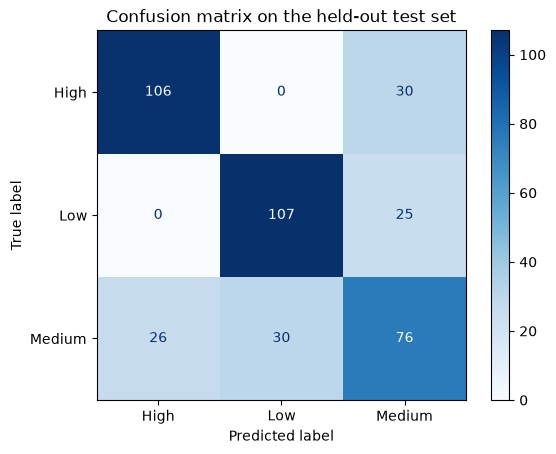

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=classes,cmap="Blues")
plt.title("Confusion matrix on the held-out test set")
plt.show()

### Analyse des erreurs et limites

In [61]:
def summarize_errors(y_true, y_pred):
    predictions = pd.DataFrame({"Classe True": y_true, "Classe Pred": y_pred})
    errors = predictions[predictions["Classe True"] != predictions["Classe Pred"]]
    return errors.value_counts().reset_index(name="Error")


error_counts = summarize_errors(y_test, y_pred)
print(f"{error_counts['Error'].sum()} erreurs sur {len(y_test)} observations.")
error_counts

ValueError: 2

In [ ]:
# Original evaluation attempt, kept for reference.
# The classification report now calculates these classification metrics together.
# from sklearn.metrics import (
#     accuracy_score,
#     precision_score,
#     recall_score,
#     f1_score,
#     confusion_matrix,
#     ConfusionMatrixDisplay,
#     roc_auc_score,
# )

# Taking the parent of the working directory assumes the kernel starts in notebooks/.
# ROOT_PATH = Path().cwd().parent
# best_pipline = load(ROOT_PATH / "models" / "best_pipeline.joblib")

# The original CSV reads treated the saved row index as a data column.
# y_test = pd.read_csv(ROOT_PATH / "artifacts" / "y_test.csv")
# y_train = pd.read_csv(ROOT_PATH / "artifacts" / "y_train.csv")
# y_test.shape,y_train.shape

# The previous version reordered the test labels using the feature index.
# y_test = y_test.reindex(X_test.index)

# This call raised the missing-columns error because y_train contains target labels.
# y_pred = best_pipline.predict(y_train)